# Housing principal component regression

Training MSE is 8,503,731,548.34 and test MSE is 8,440,870,587.90, in dollars squared. Four PCA components explain 50.72% of predictor variance; three regression components explain 62.9% of training Price variance. Scaling and PCA were fitted before the split, so the test error is exploratory.

[Housing model report](../docs/housing-model-results.md)

In [2]:

import pandas as pd

file_path = r"../data/housing_data.csv"

df = pd.read_csv(file_path)

In [3]:
df.head()

,ID,Price,SquareFootage,NumBathrooms,NumBedrooms,BackyardSpace,CrimeRate,SchoolRating,AgeOfHome,DistanceToCityCenter,...,RenovationQuality,LocalAmenities,TransportAccess,Fireplace,HouseColor,Garage,Floors,Windows,PreviousSalePrice,IsLuxury
0,4922,255614.8992,566.62,1.000000,4,779.42,20.56,5.62,39.46,10.08,...,4.93,4.44,4.55,Yes,Blue,No,1,13,181861.54230,0
1,5009,155586.0947,1472.34,1.000000,2,656.13,15.62,5.63,40.51,7.89,...,4.08,5.56,6.83,No,Green,No,1,17,50042.59757,0
2,4450,131050.8324,550.00,1.779354,3,754.57,12.47,9.20,48.38,23.74,...,4.26,8.07,8.48,Yes,Green,Yes,2,34,48400.34440,0
3,1070,151361.7125,941.81,2.035254,2,439.59,22.22,7.08,94.67,5.22,...,4.45,5.00,6.27,Yes,Red,No,1,14,84594.12145,0
4,400,113167.6128,550.00,1.064644,3,353.03,8.28,5.93,16.80,43.13,...,3.36,5.46,6.99,No,White,Yes,1,21,22934.59654,0


In [4]:
from sklearn.preprocessing import StandardScaler

# List of selected continuous variables from Part D1
continuous_vars = [
    'SquareFootage', 'NumBathrooms', 'NumBedrooms', 'BackyardSpace',
    'CrimeRate', 'SchoolRating', 'AgeOfHome', 'DistanceToCityCenter',
    'RenovationQuality', 'LocalAmenities', 'TransportAccess',
    'PreviousSalePrice', 'Windows'
]

# Extract the data to be standardized
X_continuous = df[continuous_vars]

# Standardize using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_continuous)

# Create cleaned DataFrame with standardized values
df_cleaned = pd.DataFrame(X_scaled, columns=continuous_vars)

# Save to CSV
df_cleaned.to_csv("standardized_cleaned_data.csv", index=False)

# Display the cleaned standardized dataset
df_cleaned.head()

,SquareFootage,NumBathrooms,NumBedrooms,BackyardSpace,CrimeRate,SchoolRating,AgeOfHome,DistanceToCityCenter,RenovationQuality,LocalAmenities,TransportAccess,PreviousSalePrice,Windows
0,-1.132277,-1.187828,0.970213,0.957151,-0.591776,-0.700696,-0.230889,-0.615042,-0.037232,-0.562349,-0.733870,-0.552700,-0.363983
1,0.993926,-1.187828,-0.986989,0.516683,-0.865854,-0.695399,-0.197846,-0.797175,-0.468641,-0.140939,0.433066,-1.262469,0.084154
2,-1.171293,-0.369602,-0.008388,0.868372,-1.040621,1.195478,0.049814,0.521008,-0.377284,0.803473,1.277560,-1.271312,1.988736
3,-0.251508,-0.100938,-0.986989,-0.256932,-0.499677,0.072604,1.506508,-1.019229,-0.280851,-0.351644,0.146450,-1.076429,-0.251949
4,-1.171293,-1.119960,-0.008388,-0.566178,-1.273088,-0.536502,-0.943973,2.133599,-0.834070,-0.178565,0.514957,-1.408430,0.532291


In [5]:
# Add the dependent variable back (not standardized for descriptive stats)
df_descriptive = df[["Price"] + continuous_vars]

# Show descriptive statistics
df_descriptive.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,7000.0,307281.972151,150173.433261,85000.000000,192107.531600,279322.950500,391878.127875,1.046676e+06
SquareFootage,7000.0,1048.947459,426.010482,550.000000,660.815000,996.320000,1342.292500,2.874700e+03
NumBathrooms,7000.0,2.131397,0.952561,1.000000,1.290539,1.997774,2.763997,5.807239e+00
NumBedrooms,7000.0,3.008571,1.021940,1.000000,2.000000,3.000000,4.000000,7.000000e+00
BackyardSpace,7000.0,511.507029,279.926549,0.390000,300.995000,495.965000,704.012500,1.631360e+03
CrimeRate,7000.0,31.226194,18.025327,0.030000,17.390000,30.385000,43.670000,9.973000e+01
SchoolRating,7000.0,6.942923,1.888148,0.220000,5.650000,7.010000,8.360000,1.000000e+01
AgeOfHome,7000.0,46.797046,31.779701,0.010000,20.755000,42.620000,67.232500,1.786800e+02
DistanceToCityCenter,7000.0,17.475337,12.024985,0.000000,7.827500,15.625000,25.222500,6.520000e+01
RenovationQuality,7000.0,5.003357,1.970428,0.010000,3.660000,5.020000,6.350000,1.000000e+01


In [6]:
mode_values = df_descriptive.mode().iloc[0]
mode_values.to_frame(name='mode')

,mode
Price,85000.000000
SquareFootage,550.000000
NumBathrooms,1.000000
NumBedrooms,3.000000
BackyardSpace,300.080000
CrimeRate,34.010000
SchoolRating,10.000000
AgeOfHome,18.180000
DistanceToCityCenter,8.290000
RenovationQuality,10.000000


In [7]:
from sklearn.decomposition import PCA

# Run PCA on standardized data
pca = PCA()  # No n_components specified: will return all components
principal_components = pca.fit_transform(df_cleaned)

# Create DataFrame of all principal components
pc_columns = [f'PC{i+1}' for i in range(principal_components.shape[1])]
df_pca = pd.DataFrame(principal_components, columns=pc_columns)

# Display first few rows of the full PCA matrix
df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,-0.932850,-0.372166,-1.536185,-0.065303,0.054935,0.358815,1.408982,-0.663063,-0.439749,-0.217440,-0.174650,0.954934,0.069232
1,-0.974568,0.722766,-1.091530,1.061178,0.248261,0.263322,-0.814109,-1.402829,0.639975,0.001157,0.449708,0.072990,-0.638178
2,-0.282466,1.884658,-0.703090,-0.487762,1.928024,1.701359,0.335892,0.578086,-0.339747,0.863628,0.341865,-0.761962,-0.241714
3,-1.029637,0.089956,-0.387994,0.053525,-0.518836,0.559228,-1.266409,-0.751429,-1.189122,0.715473,0.371957,-0.188399,-0.226564
4,-2.082235,1.117403,-0.978648,-1.198384,0.788054,0.680606,0.301782,1.292012,1.499867,-0.387810,0.476621,0.201149,-0.260983


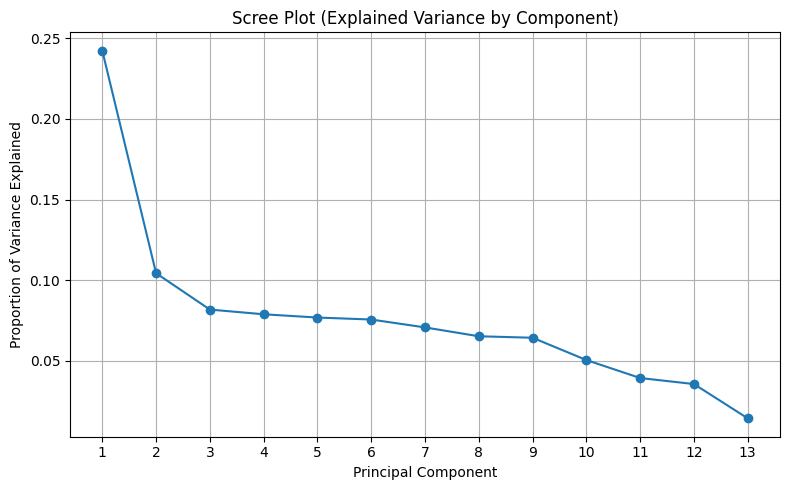

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Explained variance per component
explained_variance = pca.explained_variance_ratio_
eigenvalues = pca.explained_variance_

# Scree plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance)+1), explained_variance, marker='o', linestyle='-')
plt.title('Scree Plot (Explained Variance by Component)')
plt.xlabel('Principal Component')
plt.ylabel('Proportion of Variance Explained')
plt.grid(True)
plt.xticks(range(1, len(explained_variance)+1))
plt.tight_layout()
plt.show()

In [9]:
eigenvalues

array([3.14956509, 1.35659766, 1.06361222, 1.02561072, 0.9993829 ,
       0.98335204, 0.91975329, 0.84848357, 0.83648616, 0.65671545,
       0.51193617, 0.46334171, 0.18702042])

In [10]:
# Get the explained variance (proportion) for the first 4 components
for i, var in enumerate(explained_variance[:4], 1):
    print(f"PC{i}: {var:.4f} ({var * 100:.2f}%)")

PC1: 0.2422 (24.22%)
PC2: 0.1043 (10.43%)
PC3: 0.0818 (8.18%)
PC4: 0.0789 (7.89%)


## Principal component regression

In [11]:
# Data Splitting

from sklearn.model_selection import train_test_split

# Select only the 4 retained principal components
X_pca_selected = df_pca[['PC1', 'PC2', 'PC3', 'PC4']]

# Use original 'Price' column as the target variable (not standardized)
y = df['Price']

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X_pca_selected, y, test_size=0.2, random_state=42)

# Combine features and target into training and test DataFrames
train_df = pd.concat([X_train.reset_index(drop=True), y_train.reset_index(drop=True)], axis=1)
test_df = pd.concat([X_test.reset_index(drop=True), y_test.reset_index(drop=True)], axis=1)

# Save to CSV files
train_df.to_csv("pca_train_dataset.csv", index=False)
test_df.to_csv("pca_test_dataset.csv", index=False)

# Display head of train set
train_df.head()

,PC1,PC2,PC3,PC4,Price
0,-2.561993,0.137959,-0.078618,-0.333898,103375.7614
1,0.356523,1.650217,-1.821973,-0.209363,316030.1699
2,2.613365,-0.691762,-1.896163,0.466327,333690.0600
3,-1.001312,0.200087,-1.420386,-0.856513,122305.3568
4,-0.307120,0.280871,1.481819,-1.047979,351798.8598


In [12]:
#Initial Modeling with OLS Regression

import statsmodels.api as sm

# Add constant for intercept
X_train_const = sm.add_constant(X_train)

# Build initial OLS regression model
model = sm.OLS(y_train, X_train_const).fit()

# View full summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2367.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        07:58:24   Log-Likelihood:                -71965.
No. Observations:                5600   AIC:                         1.439e+05
Df Residuals:                    5595   BIC:                         1.440e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.082e+05   1232.940    249.939      0.0

In [13]:
# Optimization of the model

# Drop PC4
X_train_opt = X_train.drop(columns=['PC4'])
X_train_opt_const = sm.add_constant(X_train_opt)

# Refit the model
optimized_model = sm.OLS(y_train, X_train_opt_const).fit()
print(optimized_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     3156.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        07:58:24   Log-Likelihood:                -71965.
No. Observations:                5600   AIC:                         1.439e+05
Df Residuals:                    5596   BIC:                         1.440e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.082e+05   1232.763    249.972      0.0

In [14]:
from sklearn.metrics import mean_squared_error

# Predict on the training set
y_train_pred = optimized_model.predict(X_train_opt_const)

# Calculate MSE
mse_train = mean_squared_error(y_train, y_train_pred)
print(f"Training MSE: {mse_train:.2f}")

Training MSE: 8503731548.34


In [15]:
# Prepare the test data using only PC1, PC2, PC3
X_test_opt = X_test[['PC1', 'PC2', 'PC3']]
X_test_opt_const = sm.add_constant(X_test_opt)

# Predict using the optimized model
y_test_pred = optimized_model.predict(X_test_opt_const)

# Calculate MSE on test set
from sklearn.metrics import mean_squared_error
mse_test = mean_squared_error(y_test, y_test_pred)
print(f"Test MSE: {mse_test:.2f}")

Test MSE: 8440870587.90


In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF requires a constant term
X_vif = sm.add_constant(X_train_opt)

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_data

,Variable,VIF
0,const,1.000064
1,PC1,1.000031
2,PC2,1.000023
3,PC3,1.000023
